Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-prognoz-slov-rekurrentnoy-neyronnoy-setyu

In [40]:
import torch.nn as nn
import torch
from navec import Navec
import re
from torch.utils import data
from tqdm import tqdm

Будем обучать сеть предсказанию следующего слова. На вход будет поступать one-hot вектор, а на выходе будет вектор той же размерности, что и вход, и по наибольшму значению мы будет определять индекс слова в словаре. Разница с задачкой про предсказание буквы в наличии слоя эмбеддинга

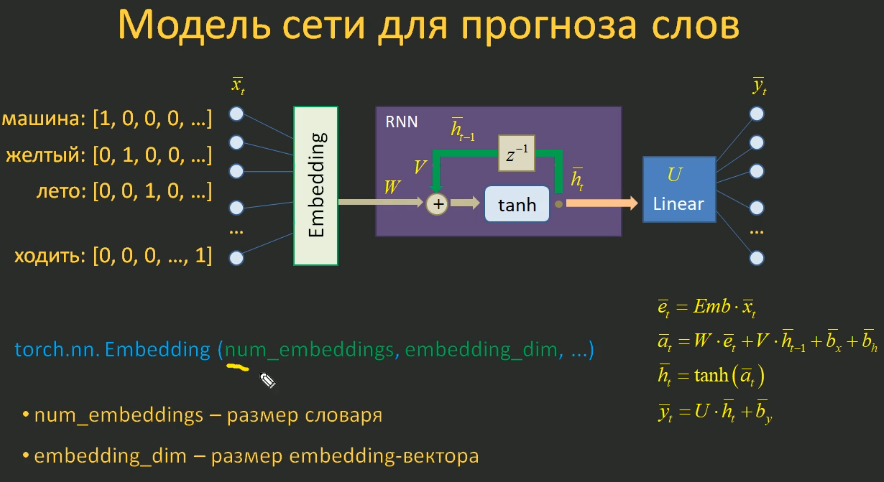

слой эмбеддинга требует размер словаря и размерность скрытого пространства (до которого надо сжать)

In [7]:
embedding = nn.Embedding(10, 4)

h = torch.tensor([1.5], dtype=torch.long)
embedding(h)

tensor([[-0.2005,  0.9394,  0.5621,  0.4356]], grad_fn=<EmbeddingBackward0>)

А можно скачать готовый эмбеддинг-вектор  
https://github.com/natasha/navec?tab=readme-ov-file#evaluation

In [8]:
path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [10]:
vector = navec['лапа']
vector

array([-0.44665733, -0.05752777,  0.32856286, -0.42389378, -0.40424848,
       -0.28197515, -0.04991828, -0.28913176,  0.18317644, -0.6062129 ,
       -0.3278433 ,  0.54578084,  0.6140734 ,  0.15814982, -0.5759709 ,
        0.33804184,  0.26323125, -0.44754174,  0.16751564, -0.37478113,
        0.05012195,  0.40567067,  0.11730886, -0.13020033, -0.0353823 ,
        0.9421046 , -0.00120435, -0.10958765, -0.33398345, -0.15277211,
       -0.21346904, -0.12314436,  0.47163716, -0.3646918 ,  0.14815423,
       -0.29767886,  0.43911347,  0.24432687,  0.07017785, -0.2605988 ,
       -0.2259032 , -0.5386131 , -0.6461731 , -0.37998885,  0.37674773,
        0.11532342, -0.23633274,  0.19544707, -0.07020655,  0.03607526,
        0.11310896,  0.17505054, -0.6939427 , -0.5640852 ,  0.0175652 ,
        0.35853836,  0.40894115, -0.14869855,  0.08035463,  0.41909438,
       -0.12709911, -0.06632375,  0.03680592, -0.1626168 , -0.5189327 ,
       -0.13273104,  0.28853622,  0.6013915 ,  0.41916054, -0.13

In [11]:
vector.shape

(300,)

In [17]:
navec['гуглить']

KeyError: 'гуглить'

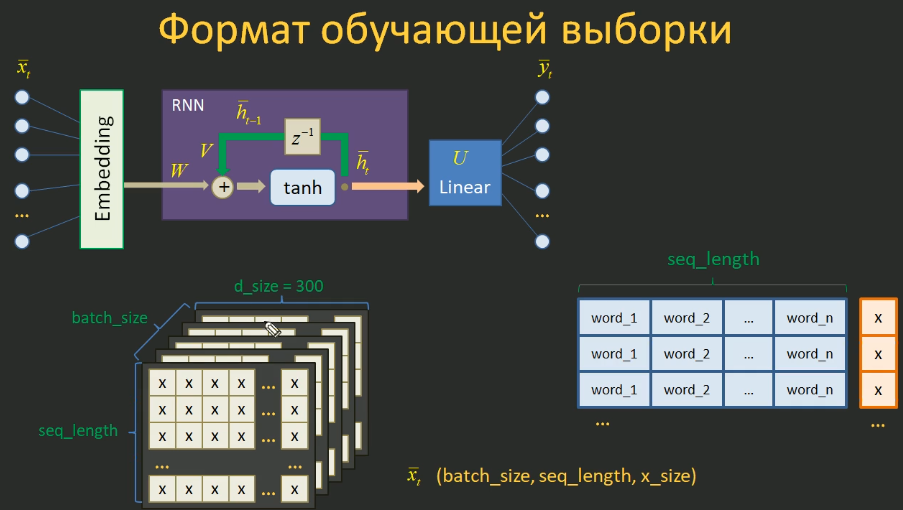

In [28]:


class WordsDataset(data.Dataset):
    def __init__(self, path, navec_emb, prev_words=3):
        self.prev_words = prev_words
        self.navec_emb = navec_emb
 
        with open(path, 'r', encoding='utf-8') as f:
            self.text = f.read()
            self.text = self.text.replace('\ufeff', '')  # убираем первый невидимый символ
            self.text = self.text.replace('\n', ' ')
            self.text = re.sub(r'[^А-яA-z- ]', '', self.text)  # удаляем все неразрешенные символы
 
        self.words = self.text.lower().split()
        self.words = [word for word in self.words if word in self.navec_emb] # оставляем слова, которые есть в словаре
        vocab = set(self.words)
 
        self.int_to_word = dict(enumerate((vocab)))
        self.word_to_int = {b: a for a, b in self.int_to_word.items()}
        self.vocab_size = len(vocab)
 
    def __getitem__(self, item):
        _data = torch.vstack([torch.tensor(self.navec_emb[self.words[x]]) for x in range(item, item+self.prev_words)])
        word = self.words[item+self.prev_words]
        t = self.word_to_int[word]
        return _data, t
 
    def __len__(self):
        return len(self.words) - 1 - self.prev_words

In [29]:
class WordsRNN(nn.Module):
    def __init__(self, in_features, out_features):
        # in_features - размер эмбеддинга
        # out_features - размер словаря
        super().__init__()
        self.hidden_size = 256
        self.in_features = in_features
        self.out_features = out_features
 
        self.rnn = nn.RNN(in_features, self.hidden_size, batch_first=True)
        self.out = nn.Linear(self.hidden_size, out_features)
 
    def forward(self, x):
        x, h = self.rnn(x)
        y = self.out(h)
        return y

In [34]:
path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

d_train = WordsDataset("text_2.txt", navec, prev_words=3)
train_data = data.DataLoader(d_train, batch_size=8, shuffle=False)
 
model = WordsRNN(300, d_train.vocab_size)

In [45]:
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001, weight_decay=0.0001)
loss_func = nn.CrossEntropyLoss()
 
epochs = 20
model.train()

for _e in range(epochs):
    loss_mean = 0
    lm_count = 0
 
    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict = model(x_train).squeeze(0)
        loss = loss_func(predict, y_train.long())
 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
 
        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

Epoch [20/20], loss_mean=0.031: 100%|██████████| 420/420 [00:06<00:00, 68.06it/s]


In [46]:
st = model.state_dict()
torch.save(st, 'model_rnn_words.tar')

In [59]:
model.eval()
predict = "ух жопа гуляша".lower().split()
total = 10
 
for _ in range(total):
    _data = torch.vstack([torch.tensor(d_train.navec_emb[predict[-x]]) for x in range(d_train.prev_words, 0, -1)])
    p = model(_data.unsqueeze(0)).squeeze(0)
    indx = torch.argmax(p, dim=1)
    predict.append(d_train.int_to_word[indx.item()])
 
print(" ".join(predict))

ух жопа гуляша мой читатель там некогда гулял и я но вреден север
